In [4]:
%pip install pillow scikit-image numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [5]:
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw, ImageEnhance, ImageFilter
from skimage import color, filters

print("NumPy:", np.__version__)
print("Pillow:", Image.__version__)
print("Todas las librerías se importaron correctamente.")

NumPy: 2.4.6
Pillow: 11.1.0
Todas las librerías se importaron correctamente.


Tamaño: (120, 120)
Modo: RGB


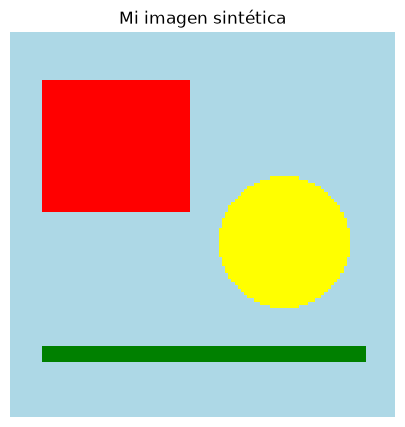

Imagen guardada como mi_imagen.png


In [6]:
# Crear una imagen RGB de 120 x 120 píxeles
img = Image.new("RGB", (120, 120), color="lightblue")

# Preparar la herramienta de dibujo
draw = ImageDraw.Draw(img)

# Figura 1: rectángulo rojo
draw.rectangle(
    [10, 15, 55, 55],
    fill="red"
)

# Figura 2: círculo amarillo
draw.ellipse(
    [65, 45, 105, 85],
    fill="yellow"
)

# Figura 3: línea verde
draw.line(
    [10, 100, 110, 100],
    fill="green",
    width=5
)

# Mostrar atributos
print("Tamaño:", img.size)
print("Modo:", img.mode)

# Mostrar imagen
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title("Mi imagen sintética")
plt.axis("off")
plt.show()

# Guardar imagen
img.save("mi_imagen.png")

print("Imagen guardada como mi_imagen.png")

In [7]:
# Reabrir la imagen guardada
imagen = Image.open("mi_imagen.png")

print("Formato:", imagen.format)
print("Tamaño:", imagen.size)
print("Modo:", imagen.mode)

# Coordenadas elegidas: (x, y)
pixel_fondo = imagen.getpixel((5, 5))
pixel_rectangulo = imagen.getpixel((20, 20))
pixel_circulo = imagen.getpixel((80, 60))

print("Píxel del fondo (5, 5):", pixel_fondo)
print("Píxel del rectángulo (20, 20):", pixel_rectangulo)
print("Píxel del círculo (80, 60):", pixel_circulo)

Formato: PNG
Tamaño: (120, 120)
Modo: RGB
Píxel del fondo (5, 5): (173, 216, 230)
Píxel del rectángulo (20, 20): (255, 0, 0)
Píxel del círculo (80, 60): (255, 255, 0)


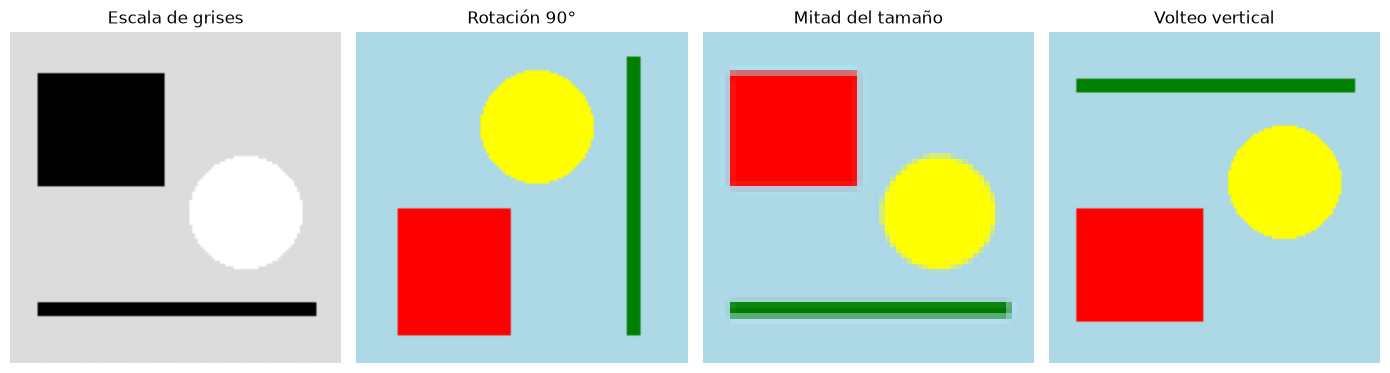

Tamaño en grises: (120, 120)
Tamaño rotado: (120, 120)
Tamaño reducido: (60, 60)
Tamaño volteado: (120, 120)


In [8]:
# 1. Convertir a escala de grises
imagen_gris_pillow = imagen.convert("L")

# 2. Rotar 90 grados
imagen_rotada = imagen.rotate(90, expand=True)

# 3. Redimensionar a la mitad
ancho, alto = imagen.size

imagen_mitad = imagen.resize(
    (ancho // 2, alto // 2)
)

# 4. Voltear verticalmente
imagen_volteada = imagen.transpose(
    Image.Transpose.FLIP_TOP_BOTTOM
)

# Mostrar resultados
fig, ejes = plt.subplots(1, 4, figsize=(14, 4))

ejes[0].imshow(imagen_gris_pillow, cmap="gray")
ejes[0].set_title("Escala de grises")

ejes[1].imshow(imagen_rotada)
ejes[1].set_title("Rotación 90°")

ejes[2].imshow(imagen_mitad)
ejes[2].set_title("Mitad del tamaño")

ejes[3].imshow(imagen_volteada)
ejes[3].set_title("Volteo vertical")

for eje in ejes:
    eje.axis("off")

plt.tight_layout()
plt.show()

print("Tamaño en grises:", imagen_gris_pillow.size)
print("Tamaño rotado:", imagen_rotada.size)
print("Tamaño reducido:", imagen_mitad.size)
print("Tamaño volteado:", imagen_volteada.size)

Píxel rojo antes: (255, 0, 0)
Píxel rojo después: (255, 0, 0)
¿Algún canal llegó a 255?: True


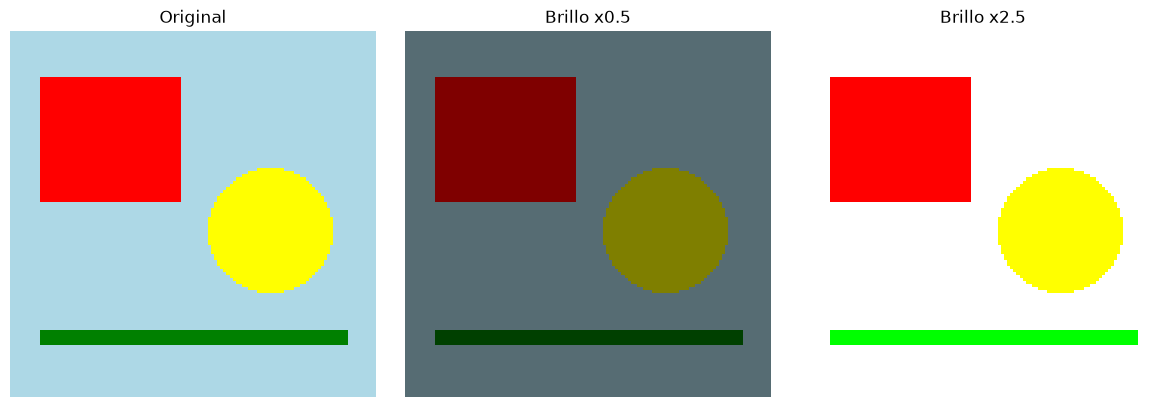

In [9]:
# Importar ImageEnhance
from PIL import ImageEnhance

# Brillo reducido
brillo_bajo = ImageEnhance.Brightness(imagen).enhance(0.5)

# Brillo aumentado
brillo_alto = ImageEnhance.Brightness(imagen).enhance(2.5)

# Comparar el píxel rojo del rectángulo
antes = imagen.getpixel((20, 20))
despues = brillo_alto.getpixel((20, 20))

print("Píxel rojo antes:", antes)
print("Píxel rojo después:", despues)

print("¿Algún canal llegó a 255?:",
      any(c == 255 for c in despues))

# Mostrar imágenes
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

ejes[0].imshow(imagen)
ejes[0].set_title("Original")

ejes[1].imshow(brillo_bajo)
ejes[1].set_title("Brillo x0.5")

ejes[2].imshow(brillo_alto)
ejes[2].set_title("Brillo x2.5")

for eje in ejes:
    eje.axis("off")

plt.tight_layout()
plt.show()

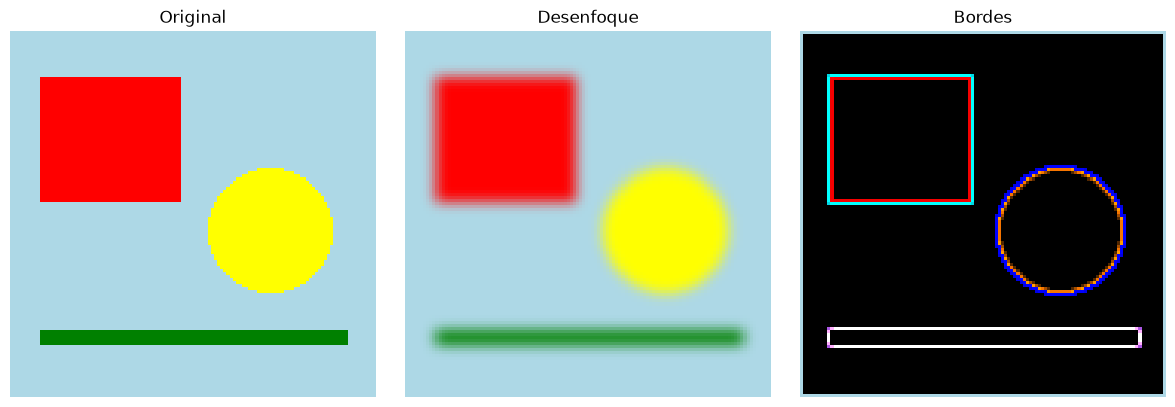

Guardados: mi_imagen_blur.png y mi_imagen_bordes.png


In [10]:
# Desenfoque gaussiano
imagen_blur = imagen.filter(
    ImageFilter.GaussianBlur(radius=2)
)

# Detección de bordes
imagen_bordes = imagen.filter(
    ImageFilter.FIND_EDGES
)

# Guardar ambos archivos
imagen_blur.save("mi_imagen_blur.png")
imagen_bordes.save("mi_imagen_bordes.png")

# Mostrar resultados
fig, ejes = plt.subplots(1, 3, figsize=(12, 4))

ejes[0].imshow(imagen)
ejes[0].set_title("Original")

ejes[1].imshow(imagen_blur)
ejes[1].set_title("Desenfoque")

ejes[2].imshow(imagen_bordes)
ejes[2].set_title("Bordes")

for eje in ejes:
    eje.axis("off")

plt.tight_layout()
plt.show()

print("Guardados: mi_imagen_blur.png y mi_imagen_bordes.png")

In [11]:
# Convertir imagen a array NumPy
imagen_array = np.array(imagen)

# Convertir RGB a escala de grises con scikit-image
gris_skimage = color.rgb2gray(imagen_array)

# Obtener la versión de Pillow
gris_pillow = np.array(imagen.convert("L"))

# Comparar el píxel de fondo (5, 5)
valor_pillow = int(gris_pillow[5, 5])
valor_skimage = float(gris_skimage[5, 5] * 255)

print("Pillow, convert('L'):", valor_pillow)
print("scikit-image, rgb2gray() x 255:", valor_skimage)
print("Diferencia absoluta:", abs(valor_pillow - valor_skimage))

Pillow, convert('L'): 205
scikit-image, rgb2gray() x 255: 207.87189999999998
Diferencia absoluta: 2.8718999999999824


Umbral de Otsu: 0.359212890625
Proporción de píxeles True: 0.8339583333333334
Porcentaje de píxeles True: 83.39583333333334 %


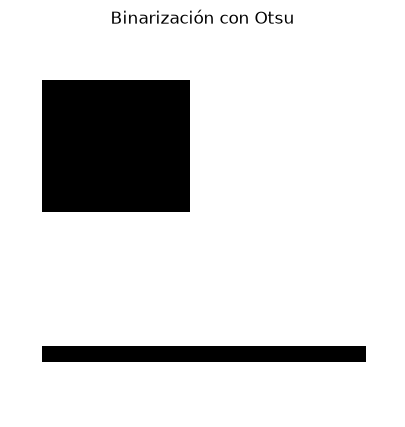

In [12]:
# Calcular el umbral de Otsu
umbral_otsu = filters.threshold_otsu(gris_skimage)

# Binarizar la imagen
imagen_binaria_otsu = gris_skimage > umbral_otsu

# Calcular la proporción de píxeles True
proporcion_true = imagen_binaria_otsu.mean()

print("Umbral de Otsu:", umbral_otsu)
print("Proporción de píxeles True:", proporcion_true)
print("Porcentaje de píxeles True:", proporcion_true * 100, "%")

# Mostrar la imagen binaria
plt.figure(figsize=(5, 5))
plt.imshow(imagen_binaria_otsu, cmap="gray")
plt.title("Binarización con Otsu")
plt.axis("off")
plt.show()

In [13]:
# Guardar las tres imágenes solicitadas
img.save("mi_imagen.png")
imagen_blur.save("mi_imagen_blur.png")
imagen_bordes.save("mi_imagen_bordes.png")

print("Imágenes guardadas correctamente:")
print("- mi_imagen.png")
print("- mi_imagen_blur.png")
print("- mi_imagen_bordes.png")

Imágenes guardadas correctamente:
- mi_imagen.png
- mi_imagen_blur.png
- mi_imagen_bordes.png
